# 03. Delivery analysis

**Purpose:** Measure how distance, weight, freight and seller handling relate to late delivery, test whether late rate follows transit time or the promised buffer, and quantify how much lateness costs in review scores.

**Inputs:** view `vw_order_base` (created by `sql/00_views.sql`) and the tables `order_items`, `sellers`, `products`, `geolocation`.

**Outputs:** `docs/figures/*.png`; `data/processed/order_features.csv` (not committed).

**Run order:** after notebooks 01 and 02 and after running `sql/00_views.sql`.

## 1. Setup

In [1]:
import os
from pathlib import Path
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

ROOT = Path.cwd().parent
load_dotenv(ROOT / ".env")

engine = create_engine(
    f"mysql+pymysql://{os.getenv('DB_USER')}:{quote_plus(os.getenv('DB_PASSWORD'))}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}?charset=utf8mb4"
)

FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

def run(sql):
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

sns.set_theme(style="whitegrid")
n_orders = run("SELECT COUNT(*) FROM vw_order_base").iloc[0, 0]
assert n_orders == 99441, "vw_order_base should have one row per order"
print(f"vw_order_base rows: {n_orders:,}")

vw_order_base rows: 99,441


## 2. One row per single-seller valid delivery

Orders are aggregated to one row (items summed, weight and volume totalled). Orders with more than one seller (about 1.3%) are excluded here, because the carrier dates exist once per order and a seller-to-customer distance would be ambiguous.

In [2]:
orders = run("""
    WITH item_agg AS (
        SELECT oi.order_id,
               MIN(oi.seller_id)                                                   AS seller_id,
               SUM(p.product_weight_g)                                             AS total_weight_g,
               SUM(p.product_length_cm * p.product_height_cm * p.product_width_cm) AS total_volume_cm3
        FROM order_items oi
        LEFT JOIN products p ON p.product_id = oi.product_id
        GROUP BY oi.order_id
    )
    SELECT b.order_id, b.customer_unique_id, b.customer_state, b.customer_zip_code_prefix,
           b.purchase_month, b.is_late, b.delay_days, b.delivery_days,
           b.seller_handling_days, b.carrier_transit_days, b.estimate_days,
           b.freight_total, b.items_revenue, b.review_score, b.n_items,
           a.seller_id, s.seller_state, s.seller_zip_code_prefix,
           a.total_weight_g, a.total_volume_cm3
    FROM vw_order_base b
    JOIN item_agg a ON a.order_id = b.order_id
    JOIN sellers  s ON s.seller_id = a.seller_id
    WHERE b.is_valid_delivery = 1
      AND b.n_sellers = 1
""")

num_cols = ["is_late", "delay_days", "delivery_days", "seller_handling_days", "carrier_transit_days",
            "estimate_days", "freight_total", "items_revenue", "review_score", "n_items",
            "total_weight_g", "total_volume_cm3"]
orders[num_cols] = orders[num_cols].apply(pd.to_numeric, errors="coerce")
orders["purchase_month"] = pd.to_datetime(orders["purchase_month"])
print(f"{len(orders):,} single-seller valid deliveries loaded")

95,029 single-seller valid deliveries loaded


## 3. Seller-to-customer distance (haversine)

The geolocation table has many rows per zip prefix, so latitude and longitude are averaged per prefix. Coordinates outside Brazil are filtered out. Distance is the straight-line (great-circle) distance between the two zip-prefix centres, not road distance.

In [3]:
geo = run("""
    SELECT geolocation_zip_code_prefix AS zip_prefix,
           AVG(geolocation_lat) AS lat,
           AVG(geolocation_lng) AS lng
    FROM geolocation
    WHERE geolocation_lat BETWEEN -34 AND 6
      AND geolocation_lng BETWEEN -74 AND -34
    GROUP BY geolocation_zip_code_prefix
""")
geo[["lat", "lng"]] = geo[["lat", "lng"]].astype(float)
print(f"{len(geo):,} zip prefixes with a centroid")

cust_geo = geo.rename(columns={"zip_prefix": "customer_zip_code_prefix", "lat": "cust_lat", "lng": "cust_lng"})
sell_geo = geo.rename(columns={"zip_prefix": "seller_zip_code_prefix", "lat": "sell_lat", "lng": "sell_lng"})

n_before = len(orders)
orders = orders.merge(cust_geo, on="customer_zip_code_prefix", how="left")
orders = orders.merge(sell_geo, on="seller_zip_code_prefix", how="left")
assert len(orders) == n_before, "merge added rows - geo has duplicate zip prefixes"

def haversine_km(lat1, lng1, lat2, lng2):
    """Straight-line distance over the Earth's surface, in km."""
    R = 6371.0
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

orders["distance_km"] = haversine_km(orders["sell_lat"], orders["sell_lng"],
                                     orders["cust_lat"], orders["cust_lng"])
orders["same_state"] = (orders["seller_state"] == orders["customer_state"]).astype(int)
orders["weight_kg"] = orders["total_weight_g"].replace(0, np.nan) / 1000
orders["volume_l"] = orders["total_volume_cm3"].replace(0, np.nan) / 1000
orders["buffer_days"] = orders["estimate_days"] - orders["delivery_days"]

print("Orders without coordinates:", int(orders["distance_km"].isna().sum()))
print(orders["distance_km"].describe().round(0))
an = orders.dropna(subset=["distance_km"]).copy()

19,010 zip prefixes with a centroid
Orders without coordinates: 471
count    94558.0
mean       601.0
std        593.0
min          0.0
25%        185.0
50%        434.0
75%        799.0
max       3399.0
Name: distance_km, dtype: float64


## 4. Spearman correlations

Spearman works on ranks, so it handles skewed data and outliers. P-values are omitted on purpose: with about 95,000 rows they are all tiny, so the size of rho is what matters.

In [4]:
cols = ["distance_km", "weight_kg", "volume_l", "freight_total", "seller_handling_days", "estimate_days"]
rows = []
for c in cols:
    d = an[["delay_days", "delivery_days", c]].dropna()
    r_delay, _ = stats.spearmanr(d[c], d["delay_days"])
    r_total, _ = stats.spearmanr(d[c], d["delivery_days"])
    rows.append({"variable": c, "n": len(d),
                 "rho_with_delay_days": round(r_delay, 3),
                 "rho_with_delivery_days": round(r_total, 3)})
display(pd.DataFrame(rows))

,variable,n,rho_with_delay_days,rho_with_delivery_days
0,distance_km,94558,-0.180,0.544
1,weight_kg,94536,-0.012,0.091
2,volume_l,94542,-0.015,0.074
3,freight_total,94558,-0.148,0.395
4,seller_handling_days,94558,0.183,0.419
5,estimate_days,94558,-0.565,0.526


## 5. Late rate by distance, and same state vs different state

,orders,late_rate_pct,avg_delivery_days,avg_estimate_days
distance_bucket,,,,
<50 km,11603,4.47,6.18,14.87
50-200,12718,4.70,8.03,17.72
200-500,29766,6.49,12.19,23.70
500-1000,25318,7.22,14.38,26.29
1000-2000,9597,9.62,18.03,30.11
2000+ km,5556,12.11,21.22,33.18


,orders,late_rate_pct,avg_delivery_days
same_state,,,
0,60432,8.14,15.22
1,34126,4.55,7.97


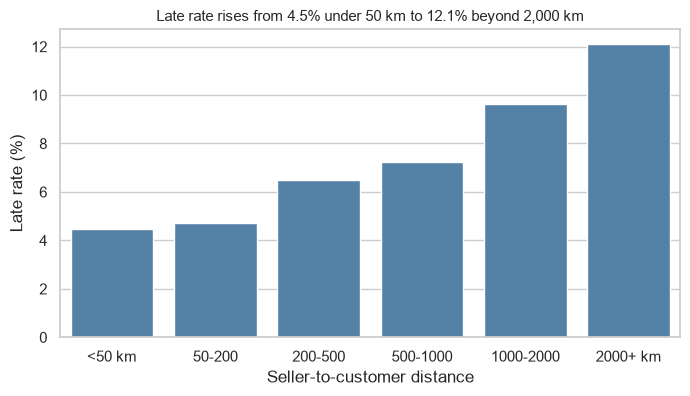

In [5]:
bins = [0, 50, 200, 500, 1000, 2000, np.inf]
labels = ["<50 km", "50-200", "200-500", "500-1000", "1000-2000", "2000+ km"]
an["distance_bucket"] = pd.cut(an["distance_km"], bins=bins, labels=labels, include_lowest=True)

dist_tbl = (an.groupby("distance_bucket", observed=True)
              .agg(orders=("is_late", "size"),
                   late_rate_pct=("is_late", lambda s: 100 * s.mean()),
                   avg_delivery_days=("delivery_days", "mean"),
                   avg_estimate_days=("estimate_days", "mean"))
              .round(2))
display(dist_tbl)

display(an.groupby("same_state")
          .agg(orders=("is_late", "size"),
               late_rate_pct=("is_late", lambda s: 100 * s.mean()),
               avg_delivery_days=("delivery_days", "mean"))
          .round(2))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=dist_tbl.reset_index(), x="distance_bucket", y="late_rate_pct", color="steelblue", ax=ax)
ax.set_xlabel("Seller-to-customer distance")
ax.set_ylabel("Late rate (%)")
ax.set_title("Late rate rises from 4.5% under 50 km to 12.1% beyond 2,000 km", fontsize=11)
fig.savefig(FIG / "late_rate_by_distance.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Delivery against the promised date, by state

The red line is the promised date. Boxes that reach it belong to states where lateness is real.

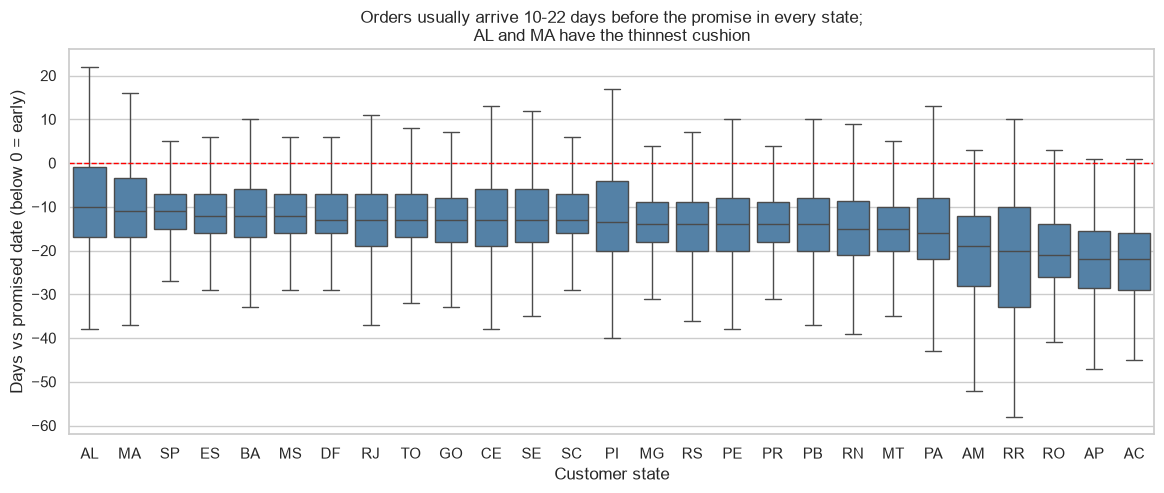

In [6]:
order = an.groupby("customer_state")["delay_days"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=an, x="customer_state", y="delay_days", order=order, showfliers=False,
            color="steelblue", ax=ax)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Customer state")
ax.set_ylabel("Days vs promised date (below 0 = early)")
ax.set_title("Orders usually arrive 10-22 days before the promise in every state;\nAL and MA have the thinnest cushion", fontsize=12)
fig.savefig(FIG / "boxplot_delay_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Does late rate follow distance or the promised buffer?

State-level check (states with 200+ orders). Buffer = promised days minus actual days.

In [7]:
state_tbl = (an.groupby("customer_state")
               .agg(orders=("is_late", "size"),
                    late_rate_pct=("is_late", lambda s: 100 * s.mean()),
                    avg_transit_days=("carrier_transit_days", "mean"),
                    avg_buffer_days=("buffer_days", "mean"),
                    avg_distance_km=("distance_km", "mean"))
               .query("orders >= 200"))

for c in ["avg_buffer_days", "avg_transit_days", "avg_distance_km"]:
    rho, _ = stats.spearmanr(state_tbl[c], state_tbl["late_rate_pct"])
    print(f"{c:18s} vs late rate: rho = {rho:+.2f}   ({len(state_tbl)} states with 200+ orders)")

avg_buffer_days    vs late rate: rho = -0.66   (23 states with 200+ orders)
avg_transit_days   vs late rate: rho = +0.69   (23 states with 200+ orders)
avg_distance_km    vs late rate: rho = +0.41   (23 states with 200+ orders)


## 8. Review score, late vs on time

Mann-Whitney compares the whole score distributions (scores are whole numbers 1-5, not bell-shaped). Cliff's delta reports how big the difference is.

In [8]:
rev = run("SELECT is_late, review_score FROM vw_order_base WHERE is_valid_delivery = 1 AND review_score IS NOT NULL")
rev = rev.apply(pd.to_numeric)
late   = rev.loc[rev["is_late"] == 1, "review_score"]
ontime = rev.loc[rev["is_late"] == 0, "review_score"]

u, p = stats.mannwhitneyu(late, ontime, alternative="two-sided")
n1, n2 = len(late), len(ontime)
cliffs_delta = 2 * u / (n1 * n2) - 1       # -1 to +1; negative = late orders score lower
prob_ontime_higher = 1 - u / (n1 * n2)     # ties counted as half

print(f"Late:    n={n1:,}  mean={late.mean():.2f}  median={late.median():.0f}  1-2 star={100*(late<=2).mean():.1f}%")
print(f"On time: n={n2:,}  mean={ontime.mean():.2f}  median={ontime.median():.0f}  1-2 star={100*(ontime<=2).mean():.1f}%")
print(f"Mean difference (late - on time): {late.mean() - ontime.mean():+.2f} points")
print(f"Mann-Whitney p-value: {p:.2e}")
print(f"Cliff's delta: {cliffs_delta:.2f}  (|d|<0.147 negligible, <0.33 small, <0.474 medium, else large)")
print(f"Chance a random on-time order outscores a random late one: {prob_ontime_higher:.1%}")

Late:    n=6,378  mean=2.27  median=1  1-2 star=62.4%
On time: n=89,258  mean=4.29  median=5  1-2 star=9.3%
Mean difference (late - on time): -2.02 points
Mann-Whitney p-value: 0.00e+00
Cliff's delta: -0.64  (|d|<0.147 negligible, <0.33 small, <0.474 medium, else large)
Chance a random on-time order outscores a random late one: 81.9%


## 9. Save the analysis table

In [9]:
an.to_csv(PROCESSED / "order_features.csv", index=False)
print("saved", len(an), "rows")

saved 94558 rows


## Findings

- **Distance:** late rate rises from 4.5% under 50 km to 12.1% beyond 2,000 km. Same-state orders are late 4.6% of the time vs 8.1% for cross-state orders.
- **Spearman (n = 94,558):** distance vs delivery days rho = 0.54, but vs delay days rho = -0.18, because Olist's estimates grow with distance (14.9 days under 50 km, 33.2 days beyond 2,000 km). Weight and volume are negligible (|rho| < 0.1).
- **State level (23 states with 200+ orders):** late rate correlates -0.66 with the average buffer, +0.69 with transit time and +0.41 with distance. This is suggestive only: the sample is small and buffer is mechanically tied to lateness.
- **Reviews:** late orders average 2.27 vs 4.29 on time (62.4% vs 9.3% give 1-2 stars). Cliff's delta = -0.64 (large); a random on-time order outscores a random late one 81.9% of the time. This is an association, not proof of cause.